In [79]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import KFold


In [81]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [82]:
df.head(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
5,referral,manufacturing,employed,africa,43841.0,3,5,0.77,1
6,NaN,education,employed,north_america,58738.0,3,9,0.78,1
7,paid_ads,technology,employed,north_america,95059.0,2,4,0.41,1
8,organic_search,healthcare,employed,asia,62565.0,3,6,0.52,1
9,referral,retail,student,asia,12000.0,2,2,0.35,0


## Data preparation

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [85]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [90]:
df.select_dtypes('object')

,lead_source,industry,employment_status,location
0,organic_search,technology,employed,europe
1,social_media,technology,employed,south_america
2,referral,retail,employed,europe
3,paid_ads,manufacturing,student,NaN
4,referral,manufacturing,student,north_america
...,...,...,...,...
4995,organic_search,education,employed,asia
4996,NaN,technology,employed,north_america
4997,organic_search,finance,employed,asia
4998,referral,technology,employed,africa


In [92]:
categorical = list(df.dtypes[(df.dtypes == 'str')].index)

In [94]:
numerical = list(df.dtypes[(df.dtypes == 'int') | (df.dtypes == 'float')].index)

In [96]:
for i in categorical:
    df[i] =  df[i].fillna("NA")

In [98]:
for i in numerical:
    df[i] =  df[i].fillna(0.0)

In [100]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## Question 1 

In [103]:
y_train = df_train.converted.values
y_val = df_val.converted.values

In [105]:
del df_train['converted']
del df_val['converted']

In [107]:
numerical = [
        'lead_score',
        'number_of_courses_viewed',
        'interaction_count',
        'annual_income'
    ]

In [109]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col:25s}: {auc:.4f}")

lead_score               : 0.7882
number_of_courses_viewed : 0.7230
interaction_count        : 0.7649
annual_income            : 0.6082


## Question 2

In [117]:
dv = DictVectorizer(sparse=False)

In [119]:
dict_train = df_train[numerical + categorical].to_dict(orient='records')
X_train = dv.fit_transform(dict_train)
dict_val = df_val[numerical + categorical].to_dict(orient='records')
X_val = dv.transform(dict_val)

In [121]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_train)[:,1]

In [123]:
(y_pred >= 0.5).mean()

0.8206666666666667

In [125]:
y_pred = model.predict_proba(X_val)[:,1]

In [127]:
auc = round(roc_auc_score(y_val, y_pred), 3)
auc

0.73

## Question 3

In [130]:
precision = precision_score(y_val, y_pred >=0.5)
precision

0.6366863905325444

In [132]:
recall = recall_score(y_val, y_pred >= 0.5)
recall

0.9180887372013652

In [134]:
thresholds = np.linspace(0, 1, 101)
thresholds

precisions = []
recalls = []
for t in thresholds:
    precision = precision_score(y_val, y_pred >= t, zero_division=0)
    recall = recall_score(y_val, y_pred >=t)
    print('t=%.2f precision=%.3f recall=%.3f' % (t, precision, recall))

    precisions.append(precision)
    recalls.append(recall)

t=0.00 precision=0.586 recall=1.000
t=0.01 precision=0.586 recall=1.000
t=0.02 precision=0.586 recall=1.000
t=0.03 precision=0.586 recall=1.000
t=0.04 precision=0.586 recall=1.000
t=0.05 precision=0.586 recall=1.000
t=0.06 precision=0.586 recall=1.000
t=0.07 precision=0.586 recall=1.000
t=0.08 precision=0.586 recall=1.000
t=0.09 precision=0.586 recall=1.000
t=0.10 precision=0.586 recall=1.000
t=0.11 precision=0.586 recall=1.000
t=0.12 precision=0.586 recall=1.000
t=0.13 precision=0.586 recall=1.000
t=0.14 precision=0.586 recall=1.000
t=0.15 precision=0.586 recall=1.000
t=0.16 precision=0.586 recall=1.000
t=0.17 precision=0.586 recall=1.000
t=0.18 precision=0.586 recall=1.000
t=0.19 precision=0.586 recall=1.000
t=0.20 precision=0.586 recall=1.000
t=0.21 precision=0.586 recall=1.000
t=0.22 precision=0.586 recall=1.000
t=0.23 precision=0.586 recall=1.000
t=0.24 precision=0.586 recall=1.000
t=0.25 precision=0.586 recall=1.000
t=0.26 precision=0.586 recall=1.000
t=0.27 precision=0.586 recal

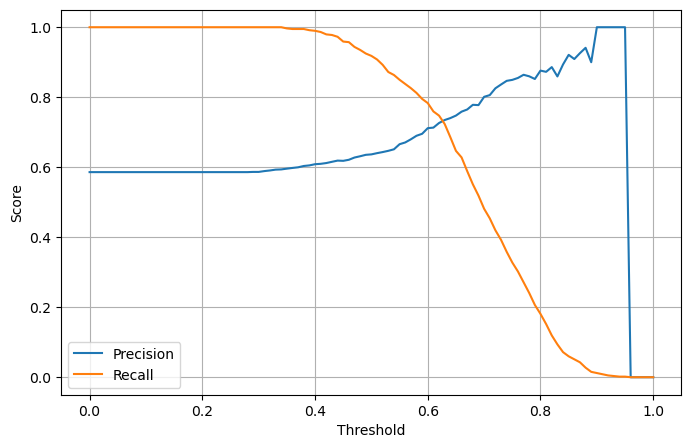

In [136]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
    
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()

## Question 4

In [139]:
f1_scores = []
for t in thresholds:
    f1 = f1_score(y_val, y_pred >= t)
    print('t=%.2f f1=%.3f' % (t, f1))
    f1_scores.append(f1)

t=0.00 f1=0.739
t=0.01 f1=0.739
t=0.02 f1=0.739
t=0.03 f1=0.739
t=0.04 f1=0.739
t=0.05 f1=0.739
t=0.06 f1=0.739
t=0.07 f1=0.739
t=0.08 f1=0.739
t=0.09 f1=0.739
t=0.10 f1=0.739
t=0.11 f1=0.739
t=0.12 f1=0.739
t=0.13 f1=0.739
t=0.14 f1=0.739
t=0.15 f1=0.739
t=0.16 f1=0.739
t=0.17 f1=0.739
t=0.18 f1=0.739
t=0.19 f1=0.739
t=0.20 f1=0.739
t=0.21 f1=0.739
t=0.22 f1=0.739
t=0.23 f1=0.739
t=0.24 f1=0.739
t=0.25 f1=0.739
t=0.26 f1=0.739
t=0.27 f1=0.739
t=0.28 f1=0.739
t=0.29 f1=0.739
t=0.30 f1=0.739
t=0.31 f1=0.741
t=0.32 f1=0.743
t=0.33 f1=0.745
t=0.34 f1=0.745
t=0.35 f1=0.746
t=0.36 f1=0.747
t=0.37 f1=0.748
t=0.38 f1=0.751
t=0.39 f1=0.752
t=0.40 f1=0.754
t=0.41 f1=0.754
t=0.42 f1=0.753
t=0.43 f1=0.755
t=0.44 f1=0.756
t=0.45 f1=0.752
t=0.46 f1=0.754
t=0.47 f1=0.754
t=0.48 f1=0.754
t=0.49 f1=0.753
t=0.50 f1=0.752
t=0.51 f1=0.751
t=0.52 f1=0.748
t=0.53 f1=0.743
t=0.54 f1=0.742
t=0.55 f1=0.747
t=0.56 f1=0.745
t=0.57 f1=0.746
t=0.58 f1=0.746
t=0.59 f1=0.742
t=0.60 f1=0.746
t=0.61 f1=0.736
t=0.62 f

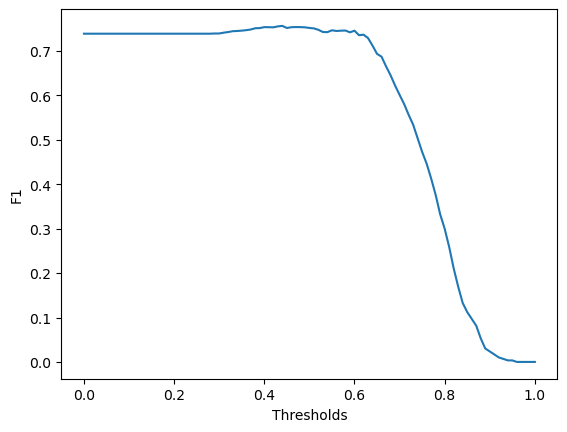

In [141]:
plt.plot(thresholds, f1_scores)
plt.xlabel('Thresholds')
plt.ylabel("F1")
plt.show()

## Question 5

In [152]:
def train (df_train, y_train, C=1.0):
    dicts = df_train[numerical + categorical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(max_iter=1000, solver='liblinear', C=C)
    model.fit(X_train, y_train)
    return dv, model

In [154]:
def predict(df, dv, model):
    dicts = df[numerical + categorical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [156]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold.split(df_full_train)

<generator object _BaseKFold.split at 0x0000018138116560>

In [158]:
scores =[]

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('Avg AUC=%.3f  AUC Std=%.3f' % (np.mean(scores), np.std(scores)))

Avg AUC=0.731  AUC Std=0.008


## Question 6

In [161]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold.split(df_full_train)

<generator object _BaseKFold.split at 0x00000181381167A0>

In [163]:
n_splits = 5

for C in [0.000001, 0.001, 1]:
    #kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s Avg AUC=%.3f AUC std=%.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 Avg AUC=0.617 AUC std=0.019
C=0.001 Avg AUC=0.746 AUC std=0.009
C=1 Avg AUC=0.731 AUC std=0.008
